# Issue 8 — MBO order-level outcomes

This notebook reads the outputs from `scripts/run_mbo_analysis.py`. The calculations are in `src/stale_quotes/mbo_analysis.py`, not in the notebook. Run the script from the repository root first.

The analysis focuses on the 0DTE ES option orders resting at prices classified as stale by Issue 6. Classifications are deliberately conservative when the order book or timestamp alignment is incomplete.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Run the notebook from notebooks/ or from the repository root.
ROOT = Path.cwd().resolve()
if not (ROOT / "issue8_report").exists() and (ROOT.parent / "issue8_report").exists():
    ROOT = ROOT.parent
DAY = "20261007"
REPORT = ROOT / "issue8_report"
DETAIL = ROOT / "data" / "processed" / "mbo" / DAY
print("Repository root:", ROOT)
assert (REPORT / f"resolution_summary_{DAY}.csv").exists(), (
    "Run scripts/run_mbo_analysis.py first, then re-run this notebook."
)

Repository root: /Users/christina/Desktop/Futures/project/issue8


In [2]:
resolution = pd.read_csv(REPORT / f"resolution_summary_{DAY}.csv")
quality = pd.read_csv(REPORT / f"data_quality_{DAY}.csv")
marks = pd.read_csv(REPORT / f"markout_summary_{DAY}.csv")
display(resolution)
display(quality)
display(marks)

,classification,count,share
0,unclassified,486,0.586957
1,modified,197,0.237923
2,mixed,82,0.099034
3,cancelled,58,0.070048
4,filled,5,0.006039


,metric,value
0,stale_pairs,828
1,unclassified,486
2,book_incomplete,0


,horizon_ms,fill_observations,valid,mean_usd,median_usd,positive_share
0,1,19,19,6.907895,2.5,0.578947
1,10,19,19,5.592105,0.0,0.421053
2,100,19,19,2.631579,2.5,0.526316


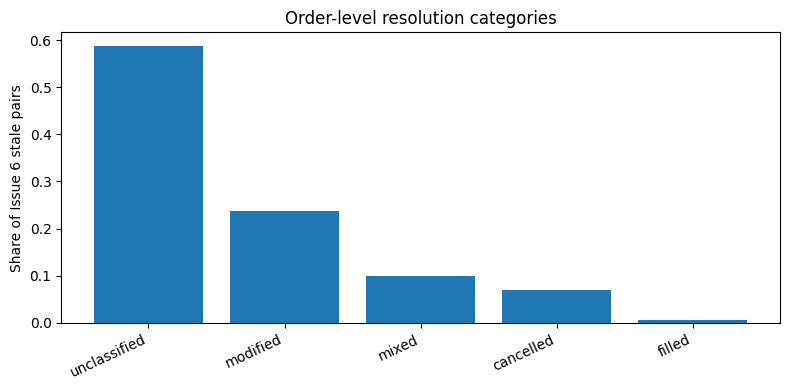

In [3]:
fig, ax = plt.subplots(figsize=(8,4))
ax.bar(resolution["classification"], resolution["share"])
ax.set(ylabel="Share of Issue 6 stale pairs",title="Order-level resolution categories")
plt.xticks(rotation=25,ha="right")
plt.tight_layout()
plt.show()

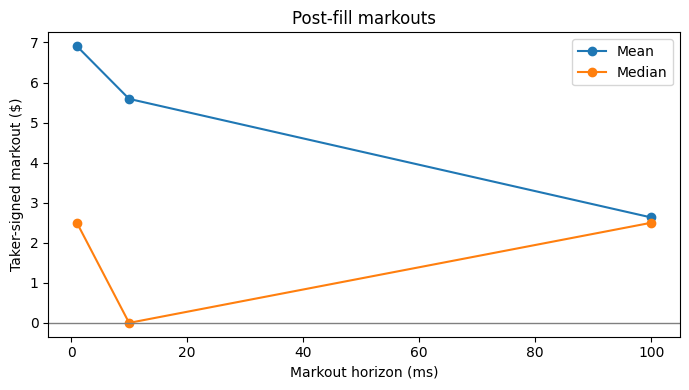

In [4]:
if not marks.empty:
    fig, ax = plt.subplots(figsize=(7,4))
    ax.plot(marks["horizon_ms"], marks["mean_usd"],marker="o",label="Mean")
    ax.plot(marks["horizon_ms"], marks["median_usd"],marker="o",label="Median")
    ax.axhline(0,linewidth=1,color="gray")
    ax.set(xlabel="Markout horizon (ms)",ylabel="Taker-signed markout ($)",title="Post-fill markouts")
    ax.legend()
    plt.tight_layout(); plt.show()
else:
    print("No eligible fills with valid markout observations.")

## Notes for interpretation

A missing initial MBO snapshot can leave older resting orders unobservable. Those cases remain unclassified rather than being treated as cancellations. Where the same order receives an `F` and its associated `C`, the records should not be counted as two separate economic actions. The markouts are comparisons against later quoted midpoints, not realized trading profits.